In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
(PROJECT_ROOT / "reports").mkdir(exist_ok=True)

# Building-age classification: exploratory data analysis

This notebook audits the **Madrid training** and **Amsterdam transfer** Parquet files. It follows an experiment-analysis structure: questions, methodology, evidence, interpretation, limitations, and next steps. Run cells in order from a fresh Python kernel. Only existing project dependencies are used; no models are trained and raw files are never modified.

**Questions / hypotheses (to investigate, not assumed results):**

1. Are labels stable across repeated years at a location, and are all four classes sufficiently represented?
2. Do cloud flags, missing observations, coverage, and temporal sampling differ between cities or classes?
3. Do spectral distributions and exploratory indices show city shift or class separation?
4. Can the available independent locations support the five few-shot budgets without reusing evaluation locations?

**Analysis units:** a raw row is a pixel–year with up to three scene observations. A location is `(city, px_key, py_key)`. Locations are not independent buildings: adjacent pixels can share buildings and urban context. City-level summaries are descriptive, not test scores. Amsterdam labels examined here make this dataset a development resource, not an untouched final test set.


## 1. Reproducible setup and input discovery

Use paths relative to the project root rather than a machine-specific absolute path. Record versions and a fixed random seed. Full audits use every row; only expensive visualizations use a reproducible sample. Parquet metadata gives schema and row counts without loading all scene strings into memory.


In [2]:
from pathlib import Path
import platform
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from IPython.display import display

SEED = 42
PLOT_SAMPLE = 40_000
BANDS = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
KEY = ['city', 'px_key', 'py_key']
ROW_KEY = KEY + ['year']
# These values are inherited from notebooks 2/3, not newly confirmed organizer rules.
CLASS_EVENTS = {'Madrid': 1960, 'Amsterdam': 1945}
BUDGETS = [5, 25, 50, 100, 200]
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').exists() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(
        'Start Jupyter inside the project, or set ROOT explicitly.')
PATHS = {c: ROOT / 'data' / f for c, f in
         [('Madrid', 'madrid_train.parquet'), ('Amsterdam', 'amsterdam_data.parquet')]}
for path in PATHS.values():
    if not path.is_file():
        raise FileNotFoundError(f'Missing input: {path}')

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.figsize': (10, 4)})

print({'python': platform.python_version(), 'pandas': pd.__version__,
       'numpy': np.__version__, 'seed': SEED, 'root': str(ROOT)})
files = {city: pq.ParquetFile(path) for city, path in PATHS.items()}
display(pd.DataFrame([{'city': c, 'rows': p.metadata.num_rows,
                       'columns': len(p.schema_arrow),
                       'file_MiB': PATHS[c].stat().st_size / 2**20}
                      for c, p in files.items()]))
schema = pd.DataFrame({c: {f.name: str(f.type) for f in p.schema_arrow}
                       for c, p in files.items()})
display(schema)
assert files['Madrid'].schema_arrow.names == files['Amsterdam'].schema_arrow.names

{'python': '3.14.4', 'pandas': '3.1.0', 'numpy': '2.5.4', 'seed': 42, 'root': '/home/mirado/hack4dev/Building_Age_Classification'}


,city,rows,columns,file_MiB
0,Madrid,3172765,48,135.383588
1,Amsterdam,1062877,48,41.809224


,Madrid,Amsterdam
pixel_id,large_string,large_string
city,large_string,large_string
year,int64,int64
px_key,int32,int32
py_key,int32,int32
pixel_x,float,float
pixel_y,float,float
row,int32,int32
col,int32,int32
coverage,float,float


## 2. Full-file schema and missingness audit

Read only the metadata needed for geographic and label audits, plus numerical spectral columns and quality flags. This avoids loading millions of scene identifiers. Missingness is computed for **every column** in streaming batches, including columns not retained in memory. Null and nonfinite are different: spectral infinities are checked later. A missing later observation slot may simply mean fewer scenes exist, rather than a corrupted measurement.


Madrid (3172765, 31) 466.0 MiB in memory
Amsterdam (1062877, 31) 162.2 MiB in memory


,Madrid missing %,Amsterdam missing %
column,,
pixel_id,0.0,0.0
city,0.0,0.0
year,0.0,0.0
px_key,0.0,0.0
py_key,0.0,0.0
pixel_x,0.0,0.0
pixel_y,0.0,0.0
row,0.0,0.0
col,0.0,0.0


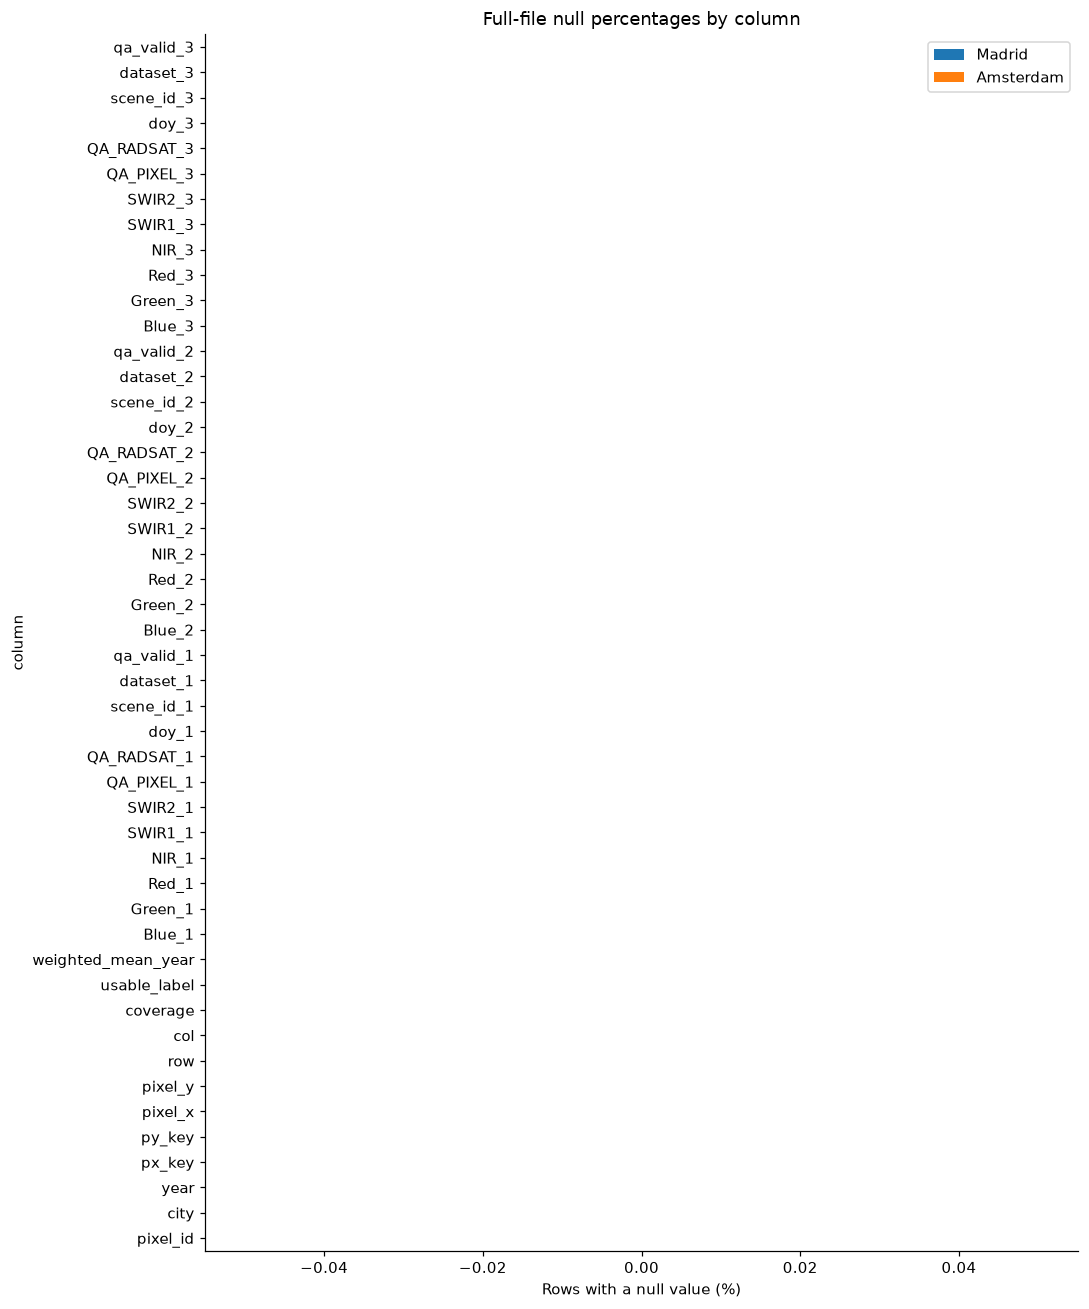

,city,px_key,py_key,pixel_id,year,pixel_x,pixel_y,coverage,usable_label,weighted_mean_year,...,SWIR2_2,Blue_3,Green_3,Red_3,NIR_3,SWIR1_3,SWIR2_3,qa_valid_1,qa_valid_2,qa_valid_3
0,Madrid,14194,149671,Madrid_14194_149671_1984,1984,425820.0,4490130.0,0.15,True,2014.000000,...,13043.585938,9323.154297,10433.227539,11603.330078,16555.982422,18056.576172,13991.788086,True,True,True
1,Madrid,14196,149670,Madrid_14196_149670_1984,1984,425880.0,4490100.0,0.17,True,2014.000000,...,13864.553711,9942.544922,11081.129883,12906.125000,17859.429688,19165.214844,14418.933594,True,True,True
2,Madrid,14259,149645,Madrid_14259_149645_1984,1984,427770.0,4489350.0,0.49,True,1950.000000,...,16026.535156,10554.107422,12373.116211,15025.377930,19446.933594,23392.283203,17264.550781,True,True,True
3,Madrid,14268,149501,Madrid_14268_149501_1984,1984,428040.0,4485030.0,0.28,True,1920.000000,...,16260.808594,9504.176758,10427.502930,11716.317383,16982.070312,17746.361328,13844.357422,True,True,True
4,Madrid,14302,149354,Madrid_14302_149354_1984,1984,429060.0,4480620.0,0.28,True,1977.178589,...,16158.819336,9440.574219,10556.319336,11596.452148,16977.035156,15927.785156,12702.273438,True,True,True


In [3]:
META = KEY + ['pixel_id', 'year', 'pixel_x', 'pixel_y', 'coverage',
              'usable_label', 'weighted_mean_year']
OBS = [f'{b}_{s}' for s in [1, 2, 3]
       for b in BANDS] + [f'qa_valid_{s}' for s in [1, 2, 3]]
raw, missing_tables = {}, {}
for city, parquet in files.items():
    required = META + OBS
    absent = set(required) - set(parquet.schema_arrow.names)
    if absent:
        raise ValueError(f'{city}: missing required columns {absent}')
    counts = dict.fromkeys(parquet.schema_arrow.names, 0)
    for batch in parquet.iter_batches(batch_size=100_000):
        for name, column in zip(batch.schema.names, batch.columns):
            counts[name] += column.null_count
    missing_tables[city] = pd.Series(counts) / parquet.metadata.num_rows
    raw[city] = pd.read_parquet(PATHS[city], columns=required)
    print(city, raw[city].shape,
          f'{raw[city].memory_usage(deep=True).sum()/2**20:.1f} MiB in memory')
missingness = pd.DataFrame(missing_tables).rename_axis('column')
display((100 * missingness).round(2).rename(columns=lambda c: c + ' missing %'))
missingness.mul(100).plot.barh(figsize=(10, 12),
                               title='Full-file null percentages by column')
plt.xlabel('Rows with a null value (%)')
plt.tight_layout()
plt.show()
display(raw['Madrid'].head())

## 3. Row integrity, label eligibility, and repeated locations

Duplicates on the location–year key can overweight observations or break temporal joins. A repeated location across years is expected. We check label consistency **before** deduplicating locations; inconsistent labels are excluded from location-level label analyses rather than silently choosing one. `usable_label` is respected for target eligibility. Out-of-range coverage or construction years are reported, not clipped away.


In [4]:
audits, locations, conflicts = [], {}, {}
for city, df in raw.items():
    grouped = df.groupby(KEY, dropna=False, observed=True)
    consistency = grouped['weighted_mean_year'].nunique(dropna=False)
    conflicts[city] = consistency[consistency > 1]
    # Eligibility is conservative: every row at a location must mark its label usable.
    loc = grouped.agg(weighted_mean_year=('weighted_mean_year', 'first'),
                      usable_label=('usable_label',
                                    lambda s: s.fillna(False).all()),
                      coverage=('coverage', 'median'), pixel_x=('pixel_x', 'first'),
                      pixel_y=('pixel_y', 'first'), n_rows=('year', 'size'),
                      n_years=('year', 'nunique'), first_year=('year', 'min'),
                      last_year=('year', 'max')).reset_index()
    loc['label_consistent'] = ~pd.MultiIndex.from_frame(
        loc[KEY]).isin(conflicts[city].index)
    locations[city] = loc
    audits.append({'city': city, 'rows': len(df), 'locations': len(loc),
                   'duplicate_location_year_rows': int(df.duplicated(ROW_KEY).sum()),
                   'missing_key_rows': int(df[ROW_KEY].isna().any(axis=1).sum()),
                   'conflicting_label_locations': len(conflicts[city]),
                   'unusable_or_null_label_rows': int((~df.usable_label.fillna(False)).sum()),
                   'invalid_coverage_rows': int((~df.coverage.between(0.15, 1)).sum()),
                   'invalid_construction_year_rows': int((~df.weighted_mean_year.between(1850, 2024)).sum()),
                   'year_min': df.year.min(), 'year_max': df.year.max()})
audit = pd.DataFrame(audits).set_index('city')
display(audit.T)
for city, loc in locations.items():
    print(city, 'rows/location quantiles:',
          loc.n_rows.quantile([0, .25, .5, .75, 1]).to_dict())

city,Madrid,Amsterdam
rows,3172765,1062877
locations,76263,25992
duplicate_location_year_rows,0,0
missing_key_rows,0,0
conflicting_label_locations,0,0
unusable_or_null_label_rows,0,0
invalid_coverage_rows,0,0
invalid_construction_year_rows,0,0
year_min,1984,1984
year_max,2025,2025


Madrid rows/location quantiles: {0.0: 13.0, 0.25: 42.0, 0.5: 42.0, 0.75: 42.0, 1.0: 42.0}
Amsterdam rows/location quantiles: {0.0: 8.0, 0.25: 41.0, 0.5: 41.0, 0.75: 42.0, 1.0: 42.0}


## 4. Derive and audit age classes

The source files contain an area-weighted construction year, not a majority-age label. Binning that mean is the existing project convention; a pixel containing old and new buildings can receive an intermediate class. This is a label-definition limitation.

We reproduce notebooks 2/3's **right-closed** boundaries: class 1 ≤ city event; class 2 > event and ≤ 1984; class 3 > 1984 and ≤ 2004; class 4 > 2004 and ≤ 2024. These differ from some informal period descriptions. Confirm both city events and exact inclusivity with organizers. Values outside 1850–2024, unusable labels, and conflicting location labels remain unlabeled. No target value is ever a predictor.


,city,boundary_year,assigned_class
0,Madrid,1960.0,1
1,Madrid,1984.0,2
2,Madrid,2004.0,3
3,Madrid,2024.0,4
4,Madrid,2025.0,<NA>


,city,boundary_year,assigned_class
0,Amsterdam,1945.0,1
1,Amsterdam,1984.0,2
2,Amsterdam,2004.0,3
3,Amsterdam,2024.0,4
4,Amsterdam,2025.0,<NA>


,Madrid,Amsterdam
age_class,,
1,13794,7568
2,27152,8802
3,18672,6745
4,16645,2877


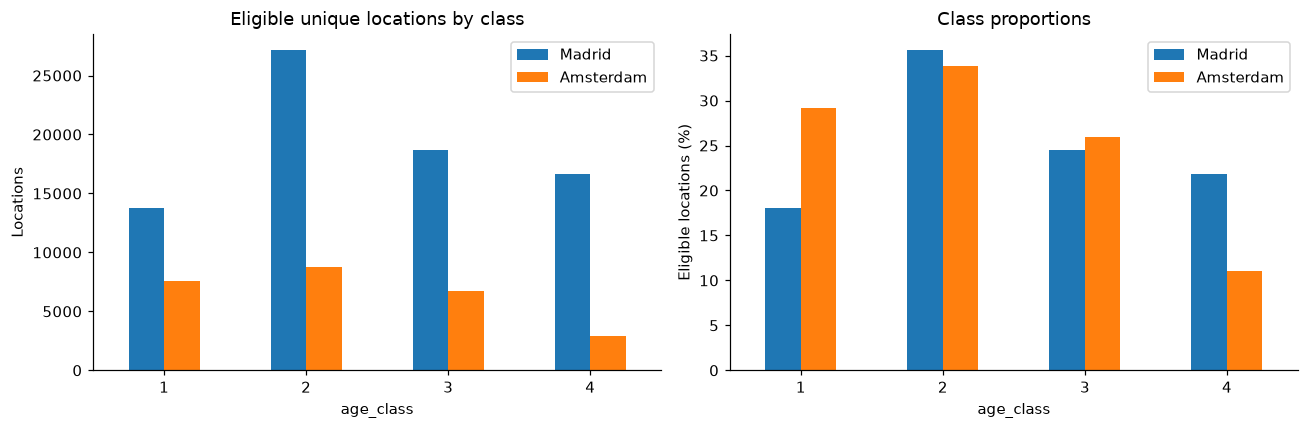

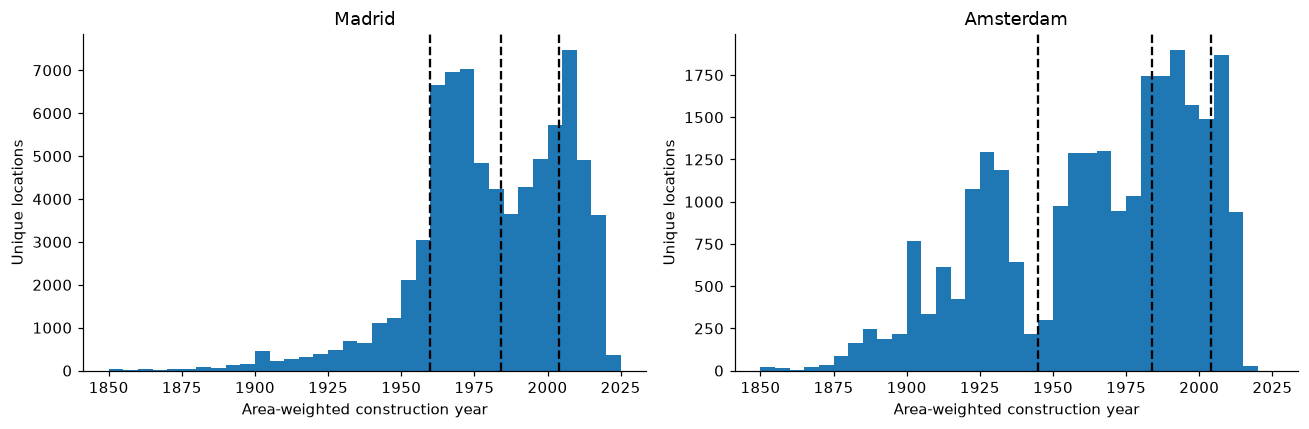

In [5]:
def age_labels(years, city):
    # An explicit lower/upper domain avoids assigning impossible years to valid classes.
    clean = years.where(years.between(1850, 2024))
    return pd.cut(clean, [-np.inf, CLASS_EVENTS[city], 1984, 2004, 2024],
                  labels=[1, 2, 3, 4], right=True).astype('Int64')


for city, loc in locations.items():
    loc['age_class'] = age_labels(loc.weighted_mean_year, city).where(
        loc.usable_label & loc.label_consistent)
    probes = pd.Series(
        [CLASS_EVENTS[city], 1984, 2004, 2024, 2025], dtype=float)
    display(pd.DataFrame({'city': city, 'boundary_year': probes,
                          'assigned_class': age_labels(probes, city)}))
class_counts = pd.DataFrame({c: loc.age_class.value_counts().reindex([1, 2, 3, 4], fill_value=0)
                             for c, loc in locations.items()}).fillna(0).astype(int)
display(class_counts.rename_axis('age_class'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.plot.bar(
    ax=axes[0], rot=0, title='Eligible unique locations by class')
class_counts.div(class_counts.sum()).mul(100).plot.bar(
    ax=axes[1], rot=0, title='Class proportions')
axes[0].set_ylabel('Locations')
axes[1].set_ylabel('Eligible locations (%)')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (city, loc) in zip(axes, locations.items()):
    ax.hist(loc.weighted_mean_year.dropna(), bins=np.arange(1850, 2030, 5))
    for boundary in [CLASS_EVENTS[city], 1984, 2004]:
        ax.axvline(boundary, color='black', ls='--')
    ax.set(title=city, xlabel='Area-weighted construction year',
           ylabel='Unique locations')
plt.tight_layout()
plt.show()

## 5. Cloud-quality flags and coherent observation selection

Select the **first QA-valid slot with all six finite bands**, keeping every band from the same scene. Choosing each band independently can synthesize a spectral vector from different dates. Earlier slots are ordered by date, not guaranteed quality rank. The audit retains all rows and records the chosen slot; rows with no complete valid slot remain missing. Do not treat QA as a guarantee that every remaining atmospheric artifact is gone.

We report a Blue > 15,000 diagnostic because the existing notebooks use that cutoff, but **do not apply it**: its physical meaning depends on the storage scale and offset, which must be confirmed from upstream metadata.


,city,slot,qa_valid_pct,complete_valid_pct,qa_valid_but_incomplete_rows,nonfinite_band_values
0,Madrid,1,95.042810,95.042810,0,0
1,Madrid,2,95.682000,95.682000,0,0
2,Madrid,3,90.055551,90.055551,0,0
3,Amsterdam,1,67.550243,67.550243,0,0
4,Amsterdam,2,75.762765,75.762765,0,0
5,Amsterdam,3,74.525086,74.525086,0,0


,raw_rows,usable_spectral_rows,usable_spectral_pct,Blue_above_15000_rows
city,,,,
Madrid,3172765,3172765,100.0,34845
Amsterdam,1062877,1062877,100.0,12917


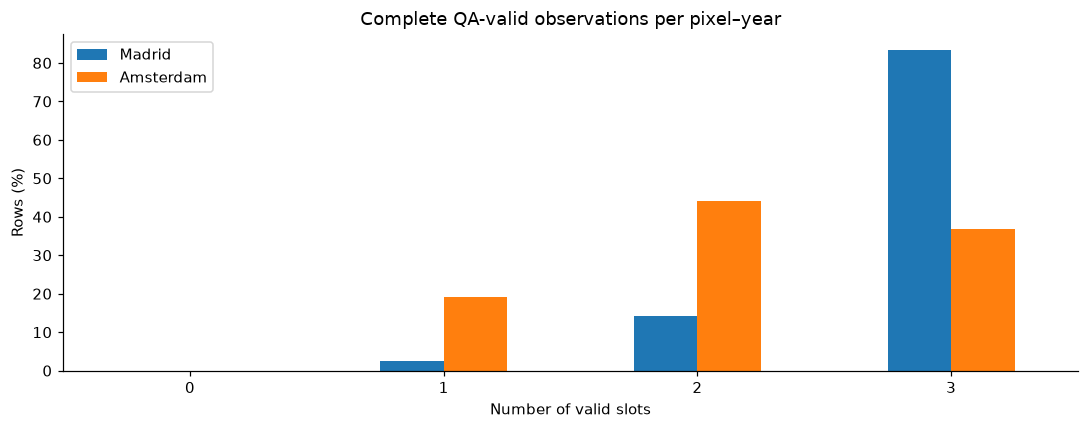

In [ ]:
flat, quality_rows = {}, []
for city, df in raw.items():
    out = df[META].copy()
    values = np.full((len(df), 6), np.nan, dtype=np.float32)
    chosen = np.zeros(len(df), dtype=np.int8)
    n_valid = np.zeros(len(df), dtype=np.int8)
    for slot in [1, 2, 3]:
        bands = df[[f'{b}_{slot}' for b in BANDS]].to_numpy(dtype=np.float32)
        qa = df[f'qa_valid_{slot}'].fillna(False).to_numpy(dtype=bool)
        complete = np.isfinite(bands).all(axis=1)
        valid = qa & complete
        n_valid += valid
        pick = (chosen == 0) & valid
        values[pick] = bands[pick]
        chosen[pick] = slot
        quality_rows.append({'city': city, 'slot': slot, 'qa_valid_pct': qa.mean()*100,
                             'complete_valid_pct': valid.mean()*100,
                             'qa_valid_but_incomplete_rows': int((qa & ~complete).sum()),
                             'nonfinite_band_values': int((~np.isfinite(bands)).sum())})
    out[BANDS] = values
    out['selected_slot'] = chosen
    out['n_valid_slots'] = n_valid
    # Attach a location-level target only after checking consistency and eligibility.
    out = out.merge(locations[city][KEY + ['age_class']],
                    on=KEY, how='left', validate='many_to_one')
    flat[city] = out
quality = pd.DataFrame(quality_rows)
display(quality)
retention = pd.DataFrame([{'city': c, 'raw_rows': len(f), 'usable_spectral_rows': int((f.selected_slot > 0).sum()),
                           'usable_spectral_pct': (f.selected_slot > 0).mean()*100,
                           'Blue_above_15000_rows': int((f.Blue > 15000).sum())}
                          for c, f in flat.items()]).set_index('city')
display(retention)
pd.DataFrame({c: f.n_valid_slots.value_counts(normalize=True).reindex(range(4), fill_value=0)*100
              for c, f in flat.items()}).plot.bar(rot=0, title='Complete QA-valid observations per pixel–year')
plt.ylabel('Rows (%)')
plt.xlabel('Number of valid slots')
plt.tight_layout()
plt.show()

## 6. Coverage, temporal sampling, and missing-data mechanisms

Compare coverage at the location level to avoid overweighting well-observed pixels. Track annual row counts and valid fractions separately: fewer retained rows can reflect cloud cover or changing sampling, not urban change. Missingness by class can become a shortcut correlated with the target. Construction dates can postdate early satellite observations; those observations describe the site **before** the labeled building existed.


Madrid observations before weighted construction year (%): 20.65


,rows,valid_fraction,median_coverage
age_class,,,
1,576190,1.0,0.53
2,1125456,1.0,0.48
3,780886,1.0,0.40
4,690233,1.0,0.43


Amsterdam observations before weighted construction year (%): 12.54


,rows,valid_fraction,median_coverage
age_class,,,
1,310054,1.0,0.38
2,363202,1.0,0.34
3,275663,1.0,0.38
4,113958,1.0,0.41


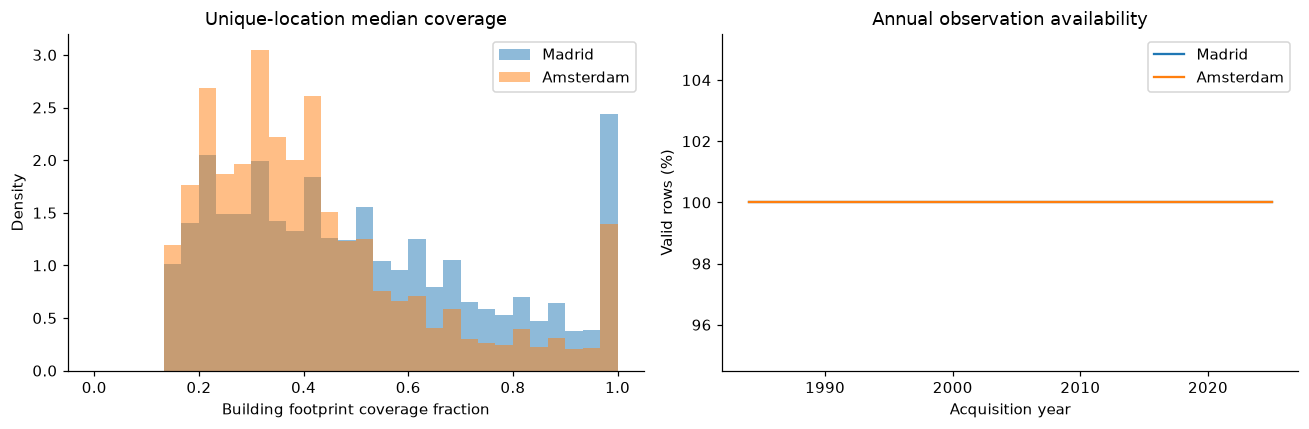

rows  valid_pct
city      year                  
Madrid    1984  75145        1.0
          1985  75532        1.0
          1986  75351        1.0
          1987  72838        1.0
          1988  74641        1.0
...               ...        ...
Amsterdam 2021  25898        1.0
          2022  25958        1.0
          2023  25834        1.0
          2024  25867        1.0
          2025  25912        1.0

[84 rows x 2 columns]

,Madrid valid years/location
count,76263.000000
mean,41.602940
std,1.872946
min,13.000000
25%,42.000000
50%,42.000000
75%,42.000000
max,42.000000


,Amsterdam valid years/location
count,25992.000000
mean,40.892467
std,2.314142
min,8.000000
25%,41.000000
50%,41.000000
75%,42.000000
max,42.000000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
annual_tables = {}
for city, f in flat.items():
    loc = locations[city]
    axes[0].hist(loc.coverage.dropna(), bins=np.linspace(
        0, 1, 31), density=True, alpha=.5, label=city)
    annual = f.assign(valid=f.selected_slot.gt(0)).groupby(
        'year').agg(rows=('year', 'size'), valid_pct=('valid', 'mean'))
    annual_tables[city] = annual
    axes[1].plot(annual.index, 100*annual.valid_pct, label=city)
    print(city, 'observations before weighted construction year (%):',
          round(100*(f.year < f.weighted_mean_year).mean(), 2))
    display(f.assign(valid=f.selected_slot.gt(0)).groupby('age_class').agg(
        rows=('year', 'size'), valid_fraction=('valid', 'mean'), median_coverage=('coverage', 'median')))
axes[0].set(xlabel='Building footprint coverage fraction',
            ylabel='Density', title='Unique-location median coverage')
axes[1].set(xlabel='Acquisition year', ylabel='Valid rows (%)',
            title='Annual observation availability')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
display(pd.concat(annual_tables, names=['city', 'year']))
# Distinct observed years, not row counts, measure temporal coverage robustly to duplicates.
observed_years = {}
for city, f in flat.items():
    observed_years[city] = f[f.selected_slot.gt(0)].groupby(KEY).year.nunique()
    total = locations[city].set_index(KEY).index
    observed_years[city] = observed_years[city].reindex(total, fill_value=0)
    display(observed_years[city].describe().to_frame(
        city + ' valid years/location'))

## 7. Spectral distributions, outliers, and feature relationships

Full-data quantiles reveal scale, negative values, and long tails. Values are kept in **stored units**; do not label them physical reflectance without verifying scale/offset. Outliers are diagnostic flags rather than automatic deletion rules. Box plots use bounded random samples and hide fliers only visually; full quantile tables still expose extremes.

For correlations and city comparisons, use one mean spectrum per location so long time series receive no extra weight. Averaging is a descriptive summary, not an endorsed final temporal representation.


Madrid full valid-row band summary


,count,mean,std,min,1%,25%,50%,75%,99%,max
Blue,3172765.0,10627.041992,1722.635376,0.000000,8552.095703,9797.726562,10391.675781,11119.679688,15184.369141,64126.003906
Green,3172765.0,11564.827148,1740.973267,0.000000,9010.515625,10546.777344,11284.374023,12224.261719,16987.628906,65454.000000
Red,3172765.0,12720.752930,2146.001953,501.000000,9285.000000,11469.709961,12477.754883,13628.262695,18862.041016,65454.000000
NIR,3172765.0,15391.948242,2239.069824,6834.000000,10878.839844,13916.857422,15277.719727,16652.683594,21794.951172,66013.406250
SWIR1,3172765.0,16108.592773,2961.096191,6987.477539,10830.080078,14219.057617,15853.537109,17630.410156,24204.945312,66655.648438
SWIR2,3172765.0,14715.393555,2627.351562,7292.775879,9886.000000,12887.000000,14479.521484,16277.975586,22029.794922,66177.242188


Nonpositive values per band: {'Blue': 23, 'Green': 1, 'Red': 0, 'NIR': 0, 'SWIR1': 0, 'SWIR2': 0}
Amsterdam full valid-row band summary


,count,mean,std,min,1%,25%,50%,75%,99%,max
Blue,1062877.0,9847.123047,4562.411133,0.000000,8150.910645,8902.000000,9281.078125,9789.898438,16051.723437,64126.003906
Green,1062877.0,10363.742188,4428.684570,3397.000000,8455.000000,9349.256836,9776.738281,10336.853516,17514.504219,62533.503906
Red,1062877.0,10726.048828,4608.086426,3547.000000,8509.000000,9579.379883,10104.035156,10760.344727,18656.167812,64388.140625
NIR,1062877.0,13587.047852,3204.141602,6643.000000,9661.000000,11898.227539,13082.812500,14575.630859,22202.141797,66013.406250
SWIR1,1062877.0,13287.183594,2447.322754,7049.520508,9763.000000,12001.000000,12931.000000,14012.585938,21977.617031,66655.648438
SWIR2,1062877.0,11987.747070,2016.501709,5122.000000,9138.689453,10942.192383,11677.327148,12550.803711,20654.166484,66177.242188


Nonpositive values per band: {'Blue': 7, 'Green': 0, 'Red': 0, 'NIR': 0, 'SWIR1': 0, 'SWIR2': 0}


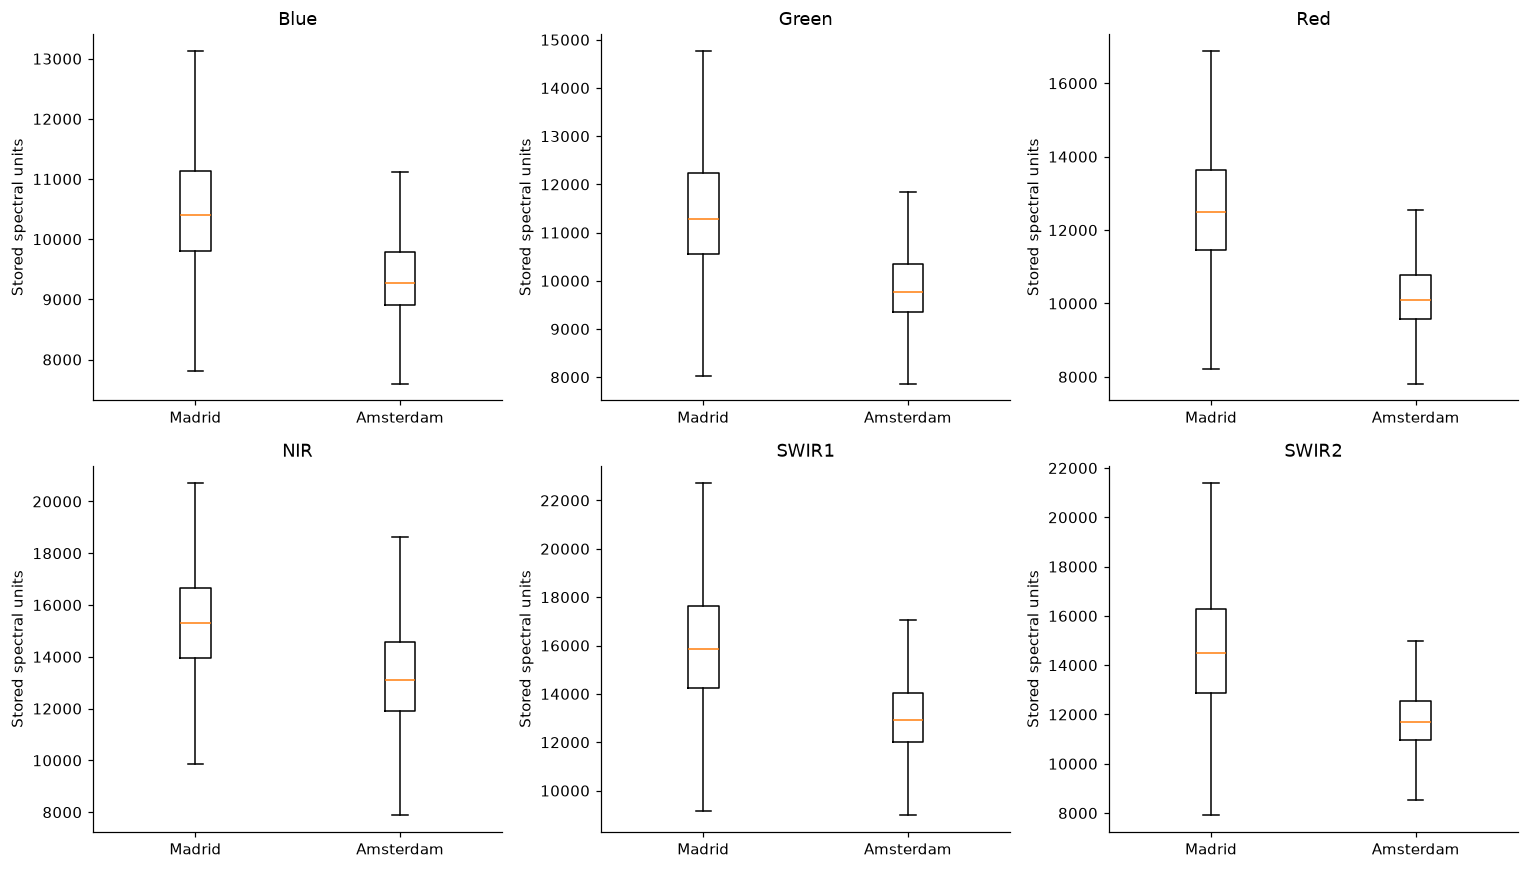

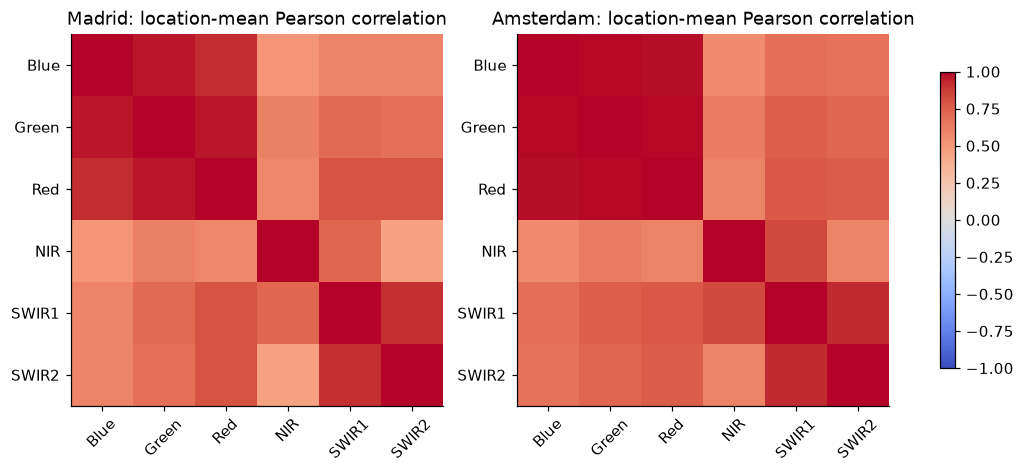

In [8]:
pixel_features = {}
for city, f in flat.items():
    valid = f[f.selected_slot.gt(0)]
    print(city, 'full valid-row band summary')
    display(valid[BANDS].describe(percentiles=[.01, .25, .5, .75, .99]).T)
    print('Nonpositive values per band:', valid[BANDS].le(0).sum().to_dict())
    means = valid.groupby(KEY)[BANDS].mean().add_suffix('_mean').reset_index()
    pixel_features[city] = locations[city].merge(
        means, on=KEY, how='left', validate='one_to_one')
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for band, ax in zip(BANDS, axes.flat):
    samples = [f.loc[f.selected_slot.gt(0), band].sample(
        min(PLOT_SAMPLE, int(f.selected_slot.gt(0).sum())), random_state=SEED).to_numpy()
        for f in flat.values()]
    ax.boxplot(samples, tick_labels=list(flat), showfliers=False)
    ax.set(title=band, ylabel='Stored spectral units')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (city, pf) in zip(axes, pixel_features.items()):
    corr = pf[[b+'_mean' for b in BANDS]].corr()
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(6), BANDS, rotation=45)
    ax.set_yticks(range(6), BANDS)
    ax.set_title(city + ': location-mean Pearson correlation')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.7)
plt.show()

## 8. Exploratory spectral indices and class profiles

NDVI contrasts vegetation-sensitive NIR and red; NDBI contrasts SWIR1 and NIR; MNDWI contrasts green and SWIR1; BSI contrasts bare-soil-sensitive band combinations. These may reveal vegetation/water/material mixtures at 30 m resolution, not building age directly. Normalized differences cancel a common multiplicative scale, **not an additive offset**. Treat these as provisional until reflectance encoding is verified.

Compute each index per selected scene before averaging per location. Near-zero denominators become missing, rather than artificial extreme values. Class profile differences are associations and do not establish out-of-city predictive performance.


,count,mean,std,min,1%,50%,99%,max
NDVI,3172765.0,0.095098,0.058087,-0.529982,0.007306,0.081687,0.284210,0.863395
NDBI,3172765.0,0.020465,0.054166,-0.676519,-0.123496,0.023910,0.127092,0.635534
MNDWI,3172765.0,-0.160927,0.055397,-1.000000,-0.278725,-0.160318,-0.028625,0.529708
BSI,3172765.0,0.048961,0.040221,-0.526767,-0.058597,0.051079,0.127557,0.554311


,count,mean,std,min,1%,50%,99%,max
NDVI,1062877.0,0.122189,0.074386,-0.473550,0.010457,0.110806,0.338800,0.803974
NDBI,1062877.0,-0.008048,0.051467,-0.715130,-0.172565,-0.000736,0.092296,0.671961
MNDWI,1062877.0,-0.130950,0.060873,-0.766938,-0.246417,-0.133280,0.006160,0.535594
BSI,1062877.0,0.013278,0.033992,-0.553946,-0.090307,0.017446,0.086153,0.531755


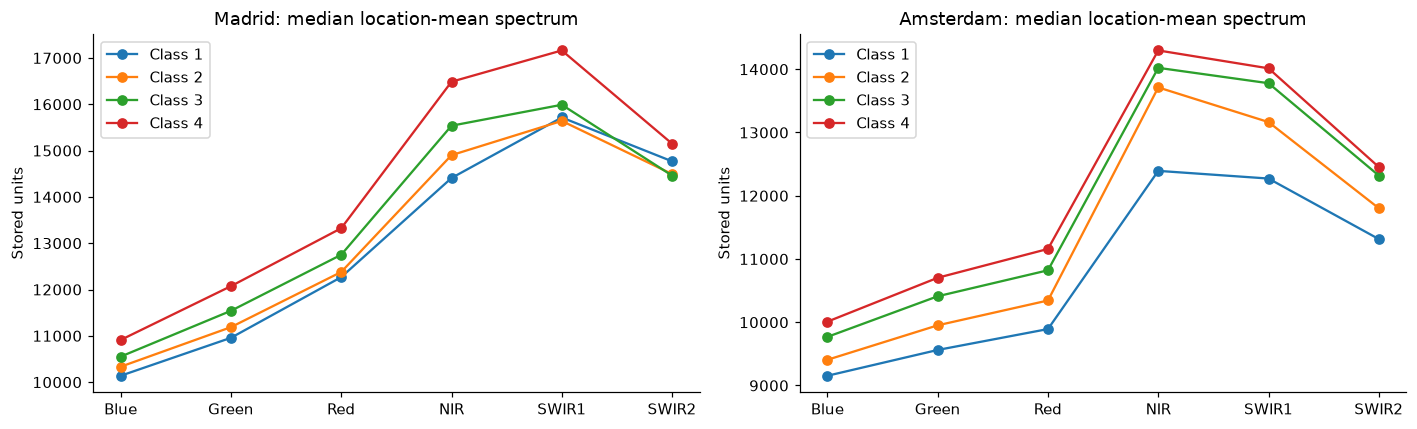

Madrid location-mean index medians by class


,NDVI_mean,NDBI_mean,MNDWI_mean,BSI_mean
age_class,,,,
1,0.071560,0.041612,-0.170882,0.062367
2,0.085143,0.022438,-0.155988,0.048652
3,0.092668,0.013974,-0.152035,0.046610
4,0.097154,0.021249,-0.167294,0.052245


Amsterdam location-mean index medians by class


,NDVI_mean,NDBI_mean,MNDWI_mean,BSI_mean
age_class,,,,
1,0.105995,-0.001557,-0.118880,0.015134
2,0.136892,-0.012642,-0.135000,0.010910
3,0.120859,-0.002842,-0.136605,0.017930
4,0.121756,-0.006309,-0.138452,0.017270


In [9]:
INDEX_NAMES = ['NDVI', 'NDBI', 'MNDWI', 'BSI']


def safe_ratio(numerator, denominator):
    return numerator.div(denominator.where(denominator.abs() > 1e-6))


for city, f in flat.items():
    b, g, r, n, s1, s2 = [f[x] for x in BANDS]
    f['NDVI'] = safe_ratio(n-r, n+r)
    f['NDBI'] = safe_ratio(s1-n, s1+n)
    f['MNDWI'] = safe_ratio(g-s1, g+s1)
    f['BSI'] = safe_ratio((s1+r)-(n+b), (s1+r)+(n+b))
    indices = f.groupby(KEY)[INDEX_NAMES].mean(
    ).add_suffix('_mean').reset_index()
    pixel_features[city] = pixel_features[city].merge(
        indices, on=KEY, validate='one_to_one')
    display(f[INDEX_NAMES].describe(percentiles=[.01, .5, .99]).T)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (city, pf) in zip(axes, pixel_features.items()):
    profile = pf.groupby('age_class')[[b+'_mean' for b in BANDS]].median()
    for cls, row in profile.iterrows():
        ax.plot(BANDS, row, marker='o', label=f'Class {cls}')
    ax.set(title=city + ': median location-mean spectrum', ylabel='Stored units')
    ax.legend()
plt.tight_layout()
plt.show()
for city, pf in pixel_features.items():
    print(city, 'location-mean index medians by class')
    display(pf.groupby('age_class')[[i+'_mean' for i in INDEX_NAMES]].median())

## 9. Cross-city shift and spatial context

Standardized mean differences quantify descriptive city shift in location means: `(Amsterdam mean − Madrid mean) / sqrt((Madrid variance + Amsterdam variance)/2)`. They are not hypothesis tests and can confound sensor, year, class mix, geography, and climate. Also compare within class, because different class proportions alone can change city averages.

Spatial plots use raw coordinate keys, whose CRS/units are not assumed. Contiguous class clusters motivate spatially separated validation; a random pixel split can still be optimistic even after repeated years are grouped.


,Amsterdam_minus_Madrid_standardized_difference
Blue_mean,-0.722428
Green_mean,-1.032678
Red_mean,-1.487749
NIR_mean,-1.230065
SWIR1_mean,-1.762062
SWIR2_mean,-1.872560
NDVI_mean,0.600689
NDBI_mean,-0.840528
MNDWI_mean,0.886418
BSI_mean,-1.447134


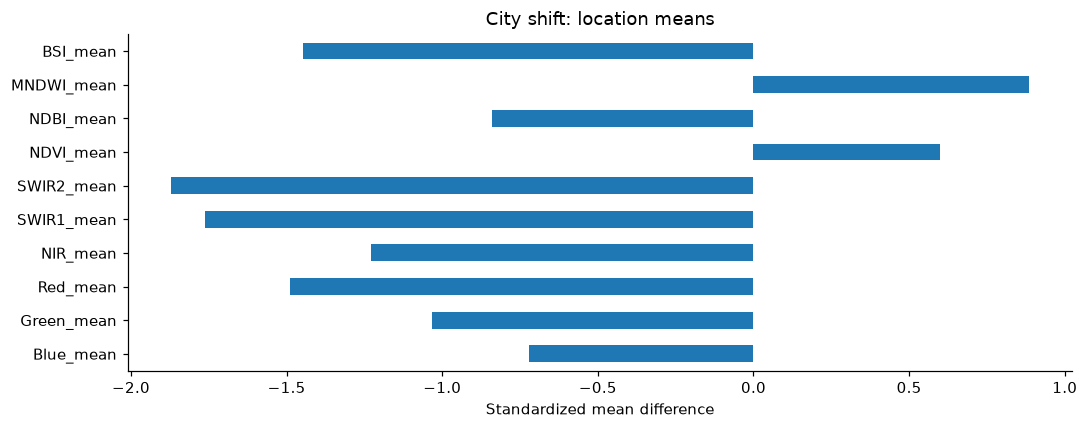

class,1,2,3,4
Blue_mean,-1.139120,-0.699306,-0.486999,-0.622231
Green_mean,-1.549705,-0.966233,-0.794901,-0.974001
Red_mean,-2.280759,-1.476806,-1.229301,-1.325232
NIR_mean,-1.666896,-0.963400,-1.123281,-1.432749
SWIR1_mean,-2.449302,-1.683666,-1.435451,-1.855535
SWIR2_mean,-2.504665,-1.859069,-1.461910,-1.764770
NDVI_mean,0.740224,0.865517,0.595852,0.372301
NDBI_mean,-1.300210,-0.988076,-0.540911,-0.701054
MNDWI_mean,1.444221,0.725958,0.598860,0.839285
BSI_mean,-1.937081,-1.490111,-1.282202,-1.266207


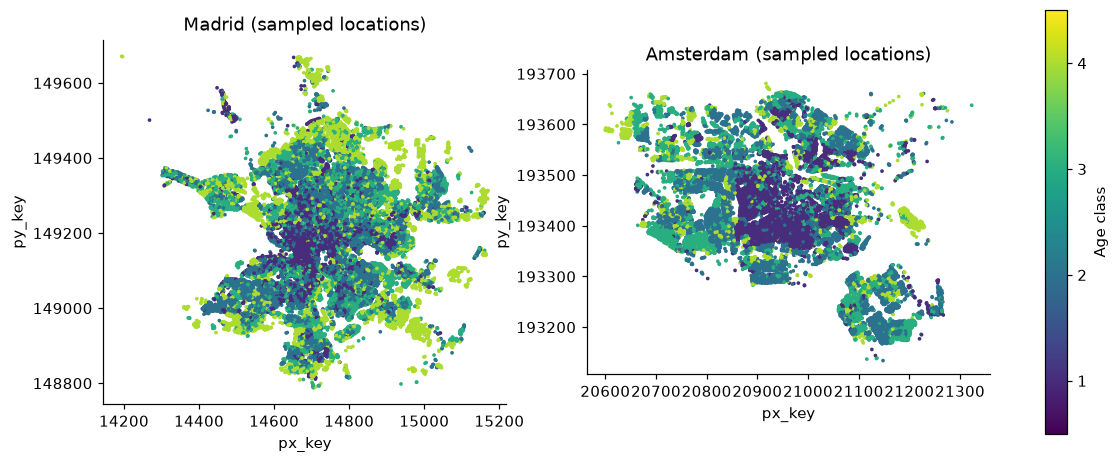

In [10]:
FEATURES = [b+'_mean' for b in BANDS] + [i+'_mean' for i in INDEX_NAMES]


def city_shift(a, b):
    denominator = np.sqrt((a.var()+b.var())/2).replace(0, np.nan)
    return (b.mean()-a.mean())/denominator


shift = city_shift(
    pixel_features['Madrid'][FEATURES], pixel_features['Amsterdam'][FEATURES])
display(shift.to_frame('Amsterdam_minus_Madrid_standardized_difference'))
shift.plot.barh(title='City shift: location means')
plt.xlabel('Standardized mean difference')
plt.tight_layout()
plt.show()
within_class = pd.DataFrame({cls: city_shift(
    pixel_features['Madrid'].loc[lambda x:x.age_class.eq(cls), FEATURES],
    pixel_features['Amsterdam'].loc[lambda x:x.age_class.eq(cls), FEATURES]) for cls in [1, 2, 3, 4]})
display(within_class.rename_axis(columns='class'))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (city, loc) in zip(axes, locations.items()):
    sample = loc.dropna(subset=['age_class']).sample(
        min(PLOT_SAMPLE, loc.age_class.notna().sum()), random_state=SEED)
    im = ax.scatter(sample.px_key, sample.py_key, c=sample.age_class.astype(int), s=2,
                    cmap='viridis', vmin=.5, vmax=4.5, rasterized=True)
    ax.set(title=city+' (sampled locations)',
           xlabel='px_key', ylabel='py_key', aspect='equal')
fig.colorbar(im, ax=axes.ravel().tolist(), ticks=[
             1, 2, 3, 4], label='Age class')
plt.show()

## 10. Few-shot feasibility and leakage-safe preparation

Count **eligible locations with at least one valid spectrum**, not repeated pixel–years. A budget `n` needs at least `n` distinct locations in each class for adaptation plus separate validation data. The table uses a configurable 20% per-class validation reserve as a feasibility illustration; it is not the official cross-validation procedure or a performance estimate. Actual spatial folds may have less capacity.

Build a predictor allowlist: exclude `weighted_mean_year`, `age_class`, `usable_label`, IDs and coordinates. Coordinates, observation year, availability and coverage can be studied separately as potential shortcuts; use only features available at deployment. No global imputation, scaling or feature selection is fitted in this notebook.


In [11]:
available = {}
for city, pf in pixel_features.items():
    available[city] = pf.loc[pf.age_class.notna(
    ) & pf[[b+'_mean' for b in BANDS]].notna().all(axis=1)].copy()
usable_counts = pd.DataFrame({c: p.age_class.value_counts().reindex([1, 2, 3, 4], fill_value=0)
                              for c, p in available.items()}).fillna(0).astype(int)
display(usable_counts.rename_axis('class'))
VALIDATION_FRACTION = .20
ams_counts = usable_counts['Amsterdam']
reserve = np.ceil(ams_counts * VALIDATION_FRACTION).astype(int)
capacity = ams_counts-reserve
feasibility = pd.DataFrame([{'samples_per_class': n, 'total_adaptation_locations': 4*n,
                             'all_classes_fit_after_reserve': bool((capacity >= n).all()),
                             'smallest_class_capacity': int(capacity.min())} for n in BUDGETS])
display(pd.DataFrame({'eligible_Amsterdam': ams_counts, 'illustrative_validation_reserve': reserve,
                      'remaining_adaptation_capacity': capacity}))
display(feasibility)
# Deliberately keep identifiers outside X: they remain available to create geographic folds.
X = {c: p[FEATURES].replace([np.inf, -np.inf], np.nan).copy()
     for c, p in available.items()}
y = {c: p.age_class.astype(int).copy() for c, p in available.items()}
groups = {c: p[KEY].copy() for c, p in available.items()}
assert not set(['weighted_mean_year', 'age_class', 'px_key',
               'py_key', 'pixel_id']) & set(FEATURES)
for city in X:
    assert len(X[city]) == len(y[city]) == len(groups[city])
    assert not groups[city].duplicated().any()
    assert set(y[city].unique()).issubset({1, 2, 3, 4})
    print(city, 'descriptive feature shape:',
          X[city].shape, 'missing predictor cells:', int(X[city].isna().sum().sum()))

,Madrid,Amsterdam
class,,
1,13794,7568
2,27152,8802
3,18672,6745
4,16645,2877


,eligible_Amsterdam,illustrative_validation_reserve,remaining_adaptation_capacity
age_class,,,
1,7568,1514,6054
2,8802,1761,7041
3,6745,1349,5396
4,2877,576,2301


,samples_per_class,total_adaptation_locations,all_classes_fit_after_reserve,smallest_class_capacity
0,5,20,True,2301
1,25,100,True,2301
2,50,200,True,2301
3,100,400,True,2301
4,200,800,True,2301


Madrid descriptive feature shape: (76263, 10) missing predictor cells: 0
Amsterdam descriptive feature shape: (25992, 10) missing predictor cells: 0


## 11. Evidence summary, limitations, and next experiments

The next cell reports data-derived findings, not prewritten conclusions. No F1 score is reported because EDA alone does not measure generalization.

**Validation protocol for subsequent modelling:**

1. Create geographic folds on unique locations; keep every year's observations of a location in its fold. Consider buffers or building-level grouping where footprints are available to reduce adjacent-pixel leakage.
2. Within each Madrid training fold, fit imputers, scalers, feature selection, and the model only on that fold. Use pipelines. Report macro F1, per-class precision/recall/F1, normalized confusion matrices, and fold mean ± standard deviation.
3. Train the final Madrid source model after design selection. For Amsterdam, reserve each outer evaluation fold before sampling 5/25/50/100/200 locations **per class** from the remaining adaptation pool. Repeat with fixed seeds; never count multiple years as separate labeled examples. Nest budgets within a repetition to improve comparisons.
4. Compare target-only, source-only, and source-plus-adaptation baselines on identical Amsterdam evaluation folds. Tune choices inside development folds; never fit on the outer evaluation fold. Keep organizer test sets untouched.
5. Compare spectral-only, indices, temporal summaries, early/late change and availability features through ablation. Use time-aware interpolation only if the prediction setting allows future observations. Do not infer unobserved early construction change by backfilling late measurements.

**Limitations:** historical city-event years and endpoint inclusivity need organizer confirmation; weighted mean is not majority construction age; spectral scaling/offset and coordinate CRS are not established here; spatial autocorrelation remains; aggregates hide sensor and temporal mixtures; descriptive exploration of Amsterdam is not independent confirmation. Data-quality rules should be selected using training data, with removal rates reported by class/city. The challenge lists five budgets despite some prose saying four scores; retain all five.


In [12]:
print('DATA-DERIVED EDA SUMMARY')
for city in PATHS:
    print(
        f'\n{city}: {audit.loc[city, "rows"]:,} raw rows; {audit.loc[city, "locations"]:,} locations.')
    print(
        f'Complete QA-valid row retention: {retention.loc[city, "usable_spectral_pct"]:.2f}%.')
    print('Eligible spectrally observed locations by class:',
          usable_counts[city].to_dict())
    print('Conflicting target locations:', len(conflicts[city]))
    print('Locations with no valid year:', int(
        observed_years[city].eq(0).sum()))
print('\nLargest absolute location-mean city shifts:')
display(shift.reindex(shift.abs().sort_values(ascending=False).index).head(
    5).to_frame('standardized_difference'))
print('All five budgets feasible under illustrative reserve:',
      bool(feasibility.all_classes_fit_after_reserve.all()))
print('Interpretation: these are descriptive diagnostics; confirm model benefits with held-out spatial evaluation.')

DATA-DERIVED EDA SUMMARY

Madrid: 3,172,765 raw rows; 76,263 locations.
Complete QA-valid row retention: 100.00%.
Eligible spectrally observed locations by class: {1: 13794, 2: 27152, 3: 18672, 4: 16645}
Conflicting target locations: 0
Locations with no valid year: 0

Amsterdam: 1,062,877 raw rows; 25,992 locations.
Complete QA-valid row retention: 100.00%.
Eligible spectrally observed locations by class: {1: 7568, 2: 8802, 3: 6745, 4: 2877}
Conflicting target locations: 0
Locations with no valid year: 0

Largest absolute location-mean city shifts:


,standardized_difference
SWIR2_mean,-1.872560
SWIR1_mean,-1.762062
Red_mean,-1.487749
BSI_mean,-1.447134
NIR_mean,-1.230065


All five budgets feasible under illustrative reserve: True
Interpretation: these are descriptive diagnostics; confirm model benefits with held-out spatial evaluation.


## 12. Optional local exports and reproducibility

Exports contain audit summaries and **unscaled** location features, not a trained preprocessing artifact. They do not replace `data/preprocessed/preprocessed_data.pkl`. Leave disabled unless wanted; enabling writes only under `data/eda`. Save this notebook with outputs to retain visual evidence. Run all cells after changing input data or boundary conventions.


In [ ]:
EXPORT = True
if EXPORT:
    output = ROOT / 'data' / 'eda'
    output.mkdir(parents=True, exist_ok=True)
    audit.to_csv(output / 'integrity_audit.csv')
    missingness.to_csv(output / 'missingness_fraction.csv')
    quality.to_csv(output / 'observation_quality.csv', index=False)
    usable_counts.to_csv(output / 'eligible_location_class_counts.csv')
    feasibility.to_csv(output / 'few_shot_feasibility.csv', index=False)
    for city, pf in pixel_features.items():
        pf.to_parquet(
            output / f'{city.lower()}_unscaled_location_features.parquet', index=False)
    (output / 'configuration.json').write_text(json.dumps({
        'seed': SEED, 'class_events': CLASS_EVENTS, 'right_closed_bins': True,
        'budgets': BUDGETS, 'features': FEATURES, 'inputs': {c: str(p) for c, p in PATHS.items()}}, indent=2))
    print('Exports saved:', output)
else:
    print('Export disabled. Raw inputs and existing preprocessing artifacts were not changed.')